# Lab 04: What is an agent

## Goal

Ask one everyday question three ways, to a chatbot, a workflow and an agent, and see that they differ in one thing:
**who decides the next step**. That test gives us the definition of an agent. Then we take the same three shapes to
the Chinook music shop's support desk. There the chatbot answers a question about a customer at once, fluently, with
nothing looked up, and only the database can say which parts of its answer are true. The agent then answers a
question nobody wrote steps for. We end by deciding how far an agent should be allowed to act on its own.

This notebook has two halves: a playground on a two-order shop (Parts A to D), then the Chinook support desk
(Parts E to G).

## What you will learn

- How to tell a chatbot, a workflow and an agent apart by asking who decides the next step.
- How to write a workflow (fixed steps in our code; ours makes no model call), and what it does with a question it
  was not written for.
- How a small agent works: the model asks for a lookup, our code runs it, the model answers from the result.
- The definition of an agent, and where its six parts are in code we have just run.
- Why an answer the model writes with nothing looked up is no evidence, even when part of it is right.
- How to choose an autonomy level (suggest, draft, act with audit, act) for a job, and when not to use an agent.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model name from `models.env`, and
takes the key from `.env` without printing it.

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


We call the model with Chat Completions, the plain request-and-reply API. Agent frameworks build their loops on
calls like these, so we start with the plain call. The client waits at most 60 seconds for a reply, and every call
passes `reasoning_effort=EFFORT or omit` (`omit` leaves the argument out when `models.env` sets no effort).

In [2]:
import json
from openai import OpenAI, omit

client = OpenAI(timeout=60)

---

## Part A: Ask a chatbot about an order it cannot see

We start with a question anyone could ask a small online shop:

> What is the status of order B22?

The shop's order records are a Python dictionary with two orders. It stands in for a real order system, and it lets
us read the right answer before any model is involved.

In [3]:
ORDERS = {
    "A17": "shipped on 3 November",
    "B22": "waiting for stock",
}

QUESTION = "What is the status of order B22?"
print(ORDERS["B22"])

waiting for stock


B22 is waiting for stock. Every reply in Parts A to C is checked against this dictionary.

### A chatbot: one model call with no tools

A **chatbot**, in this lab, is one model call: the question goes in, a reply comes out, and nothing else happens.
The request carries two messages:

- the `system` message, `SYSTEM`: what the assistant is for. The agent in Part C uses the same text, so the only
  differences between the two will be the tool and the loop that runs it;
- the `user` message: the customer's question.

In [4]:
SYSTEM = "You help customers of a small online shop with questions about their orders. Answer in one or two sentences."

response = client.chat.completions.create(
    model=MODEL,
    messages=[
        {"role": "system", "content": SYSTEM},
        {"role": "user", "content": QUESTION},
    ],
    reasoning_effort=EFFORT or omit,
)

print(response.choices[0].message.content)

I can check that for you, but I don’t have access to order records here. Please share your order confirmation or contact the shop’s support team for the latest status.


In our run the model wrote: *I can check that for you, but I don’t have access to order records here. Please share
your order confirmation or contact the shop’s support team for the latest status.*

Read the two halves. The first says it can check; the second says it cannot, and the second is what happened: the
reply gives no status. The dictionary `ORDERS` lives in our Python, and the request carried only the two messages
above, so the model had nothing to read the status from. It said so instead of making one up.

**Who decided the next step?** Nobody. The model wrote one reply, and there was no next step to decide: a chatbot
has no way to look anything up.

**Checkpoint A.** One reply, and no order status taken from `ORDERS`. Your wording will differ; ours said it had no access to the order records.

---

## Part B: Answer the same question with a workflow

The answer is in our dictionary, so plain code can fetch it. A **workflow** is a fixed set of steps that our code
runs in an order we wrote in advance. Ours has three steps and no model call:

1. **Find the order id in the question.** `re.findall(pattern, text)` returns every piece of `text` that matches the
   pattern, as a list. Our pattern `\b[A-Z]\d{2}\b` means one capital letter followed by two digits, standing as a
   word of its own (`\b` marks the edge of a word): `B22` matches, `B223` does not.
2. **Look the id up** in `ORDERS`. `.get(order_id, "no such order")` gives the second value when the id is not a key.
3. **Write the reply** from a fixed sentence.

In [5]:
import re


def order_workflow(question):
    # Step 1: find the order ids in the question
    order_ids = re.findall(r"\b[A-Z]\d{2}\b", question)
    if not order_ids:
        return "Please tell me your order id, for example B22."

    # Step 2: look up the first id. Step 3: write the reply from a fixed sentence
    order_id = order_ids[0]
    return f"Order {order_id}: {ORDERS.get(order_id, 'no such order')}."


print(order_workflow(QUESTION))

Order B22: waiting for stock.


The right answer, with no model call. It costs nothing, and it gives exactly this reply every time we run it.

Now a question that is only a little different. Before you run it: what will the workflow reply?

In [6]:
print(order_workflow("Have orders A17 and B22 shipped yet?"))

Order A17: shipped on 3 November.


`Order A17: shipped on 3 November.`, and nothing about B22. Step 1 finds both ids:
`re.findall(r"\b[A-Z]\d{2}\b", "Have orders A17 and B22 shipped yet?")` returns `['A17', 'B22']`. To see it,
paste that line into a new cell and run it (`re` is already imported). Step 2 looks up only the first,
`order_ids[0]`, because that is the step we wrote. The reply reads like a full answer: nothing in it says that B22
was skipped. To answer this question, someone has to change the code.

**Who decided the next step?** We did, in advance, when we wrote `order_workflow`. That is why it is right every
time on the questions we planned for, and why a new kind of question needs new code.

**Checkpoint B.** `Order B22: waiting for stock.` for the first question, with no model call. For *Have orders A17
and B22 shipped yet?*, a reply about A17 only.

---

## Part C: Let an agent look the order up

The chatbot could not look. The workflow could look, but only along the steps we wrote. An **agent** divides the
work between the model and our code: the model decides which lookup to ask for, our code runs it and sends the
result back, and the model answers from it. This is the agent loop, written here in a few lines (Lab 03 builds it step by step).

### The lookup as a tool

`get_order_status` is ordinary Python. Its first line prints `TOOL CALLED`, so we can see each time it really runs.
The model never sees this code. It sees `ORDER_TOOL`, a description of the function, a **tool schema**:

- `name`: what the model writes to ask for the tool;
- `description`: what the tool is for. The model chooses tools by reading it;
- `parameters`: the arguments, as a JSON Schema: one string called `order_id`;
- `strict: True`: the model's arguments must match the schema exactly.

We call the function once ourselves, before any model is involved.

In [7]:
def get_order_status(order_id: str) -> str:
    """Look up the status of one order by its id, for example 'B22'."""
    print(f"TOOL CALLED: get_order_status({order_id})")
    return ORDERS.get(order_id, "no such order")


ORDER_TOOL = {
    "type": "function",
    "function": {
        "name": "get_order_status",
        "description": "Look up the status of one order by its id, for example 'B22'.",
        "parameters": {
            "type": "object",
            "properties": {"order_id": {"type": "string"}},
            "required": ["order_id"],
            "additionalProperties": False,
        },
        "strict": True,
    },
}

print(get_order_status("B22"))

TOOL CALLED: get_order_status(B22)
waiting for stock


### The loop

`order_agent` runs these steps:

1. Start a `messages` list with the system message and the question.
2. Call the model with the whole list and the tool, and add its reply to the list.
3. If the reply asks for no tool, it is the answer: return it.
4. Otherwise, for each tool call in the reply, run the function with the arguments the model wrote, and add the
   result to the list as a `tool` message with the call's `id`, so the model can match the result to its request.
5. Go round again, at most `max_turns` times. A **turn** is one call to the model. If the cap is reached, return
   `None`: there is no answer.

Two Python details carry the tool call. The model writes the arguments as a string of JSON, such as
`{"order_id":"B22"}`; `json.loads` turns it into a dictionary, and `**args` passes that dictionary to the function as
`order_id="B22"`.

Each turn prints one line, so we can see who asked for what.

In [8]:
def order_agent(question, max_turns=5):
    messages = [
        {"role": "system", "content": SYSTEM},
        {"role": "user", "content": question},
    ]
    for turn in range(1, max_turns + 1):
        response = client.chat.completions.create(
            model=MODEL, messages=messages, tools=[ORDER_TOOL], reasoning_effort=EFFORT or omit
        )
        reply = response.choices[0].message
        messages.append(reply)

        # Exit 1: the model answered
        if not reply.tool_calls:
            print(f"turn {turn}: the model answers")
            return reply.content

        # The model asked for lookups: our code runs each one and sends the result back
        for call in reply.tool_calls:
            print(f"turn {turn}: the model asks for {call.function.name}({call.function.arguments})")
            args = json.loads(call.function.arguments)
            result = get_order_status(**args)
            messages.append({"role": "tool", "tool_call_id": call.id, "content": result})

    # Exit 2: the turn cap stopped the loop, and there is no answer
    return None

Before you run it: how many turns will the B22 question take?

In [9]:
print(order_agent(QUESTION))

turn 1: the model asks for get_order_status({"order_id":"B22"})
TOOL CALLED: get_order_status(B22)


turn 2: the model answers
Order B22 is currently waiting for stock.


Three lines, in this order:

1. `turn 1: the model asks for get_order_status({"order_id":"B22"})`. The first reply is a request: a tool name,
   and an argument the model wrote from the question. Nothing has run yet, and nothing has been answered.
2. `TOOL CALLED: get_order_status(B22)`. Our code ran the function, and its result, *waiting for stock*, went into
   `messages` as a `tool` message.
3. `turn 2: the model answers`. The second call sent the whole list, result included, and this time the reply is
   the answer: *Order B22 is currently waiting for stock.*

Two model calls and one lookup, and the answer matches `ORDERS`.

**Who decided the next step?** The model. It chose to call `get_order_status`, chose `B22` as the argument, and
chose to stop after one lookup. Our code ran what it asked for, and nothing else.

### The two-order question, asked of the agent

Now the question from Part B, to the same `order_agent`, with no change to its code.

In [10]:
print(order_agent("Have orders A17 and B22 shipped yet?"))

turn 1: the model asks for get_order_status({"order_id": "A17"})
TOOL CALLED: get_order_status(A17)
turn 1: the model asks for get_order_status({"order_id": "B22"})
TOOL CALLED: get_order_status(B22)


turn 2: the model answers
A17 shipped on 3 November. B22 is still waiting for stock and hasn’t shipped yet.


In our run the first reply asked for **two** lookups at once, `A17` and `B22`, so both `TOOL CALLED` lines come
under turn 1. The second reply answered both: *A17 shipped on 3 November. B22 is still waiting for stock and hasn’t
shipped yet.* Two model calls again.

We changed nothing in `order_agent`. The model read the question, found two order ids in it, and asked for two
lookups. The workflow needed new code for that.

**Checkpoint C.** For the B22 question: a request for `get_order_status` with `{"order_id":"B22"}`, one
`TOOL CALLED` line, and an answer that B22 is waiting for stock, in two model calls. For the two-order question: two
`TOOL CALLED` lines and an answer about both orders. The model may ask for the two orders in one reply or one after the other; both are right.

---

## Part D: Define an agent by who decides the next step

We have now asked one question three ways. The drawing puts the three shapes side by side. The dark boxes are the
model's steps, the lime boxes are our code's.

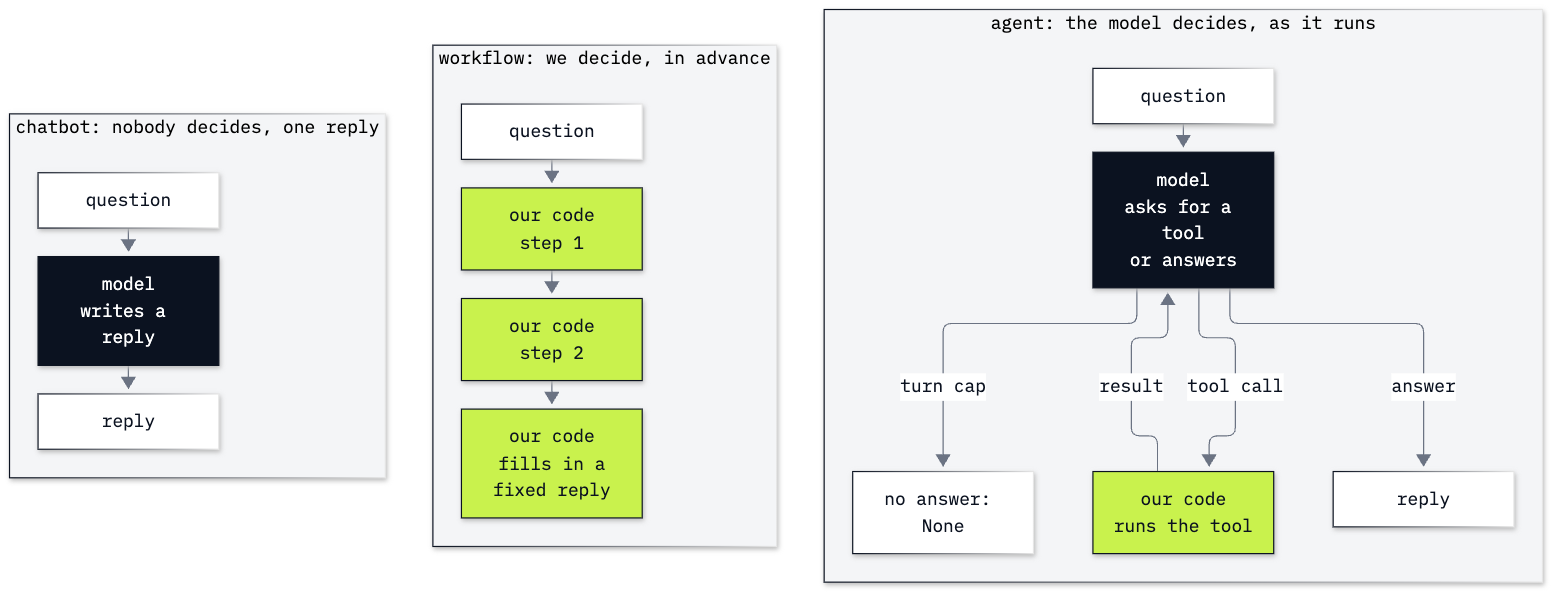

In [11]:
from IPython.display import Image

Image("resources/lab04_three_shapes.png", width=760)

What each shape did with *What is the status of order B22?* in our runs:

| Shape | What happened | Model calls | Who decides the next step |
|---|---|---|---|
| Chatbot | said it had no access to the order records, and gave no status | 1 | nobody: one reply |
| Workflow | `Order B22: waiting for stock.`, from steps we wrote | 0 | we do, in advance |
| Agent | asked for `get_order_status`, our code ran it, then it answered | 2 | the model, as it runs |

All three can use the same model. What differs is who picks the next step, and so what each one can answer.

This gives us the definition the rest of these labs use:

> **Agent:** a system in which a model decides the next step: which tool to use, with what input, and when to stop.

Read it against `order_agent`'s two runs. **Which tool:** `get_order_status`, the only one it had. **With what
input:** `B22` the first time, `A17` and `B22` the second; nobody wrote those values into the code. **When to stop:**
after one lookup, then after two.

**Important:** an agent is not a better model. The same model, with the same `SYSTEM` text, wrote the chatbot's reply
in Part A. What changed between Part A and Part C is the tool we described and the loop our code runs.

A workflow may call a model too, at a step we fixed: for example, to write the reply in friendlier words than our
f-string. It is still a workflow, because our code chose the steps. Ours made no model call, so all of its deciding
is visible in the code.

### The six parts of an agent, in `order_agent`

An agent has six parts, and only one of them is the model:

| Part | What it is | Where it is in our code |
|---|---|---|
| Model | writes either a tool request or the answer | `client.chat.completions.create(model=MODEL, ...)` |
| Instructions | what the assistant is for | `SYSTEM` |
| Tools | functions our code may run, described to the model | `get_order_status`, described by `ORDER_TOOL` |
| Memory | what the model sees of the work so far | the `messages` list, sent whole on every turn |
| The loop | call the model, run what it asks for, send the results back, repeat | `for turn in ...`, with its two exits |
| Guardrails | checks on what goes in and what comes out | only `max_turns`, and `.get(..., "no such order")` for an unknown id |

The other five are our code. Our guardrails are thin on purpose: this agent only reads a dictionary. An agent that
can change something needs real checks, and Part G comes back to that.

**Checkpoint D.** Answer in a sentence each. Which of the six parts would you change so that the agent could also
cancel an order? Which part would you want a check in before it does? Our answers are in
`solved/04_what_is_an_agent_solution.ipynb`.

---

## From the playground to the desk

Now we take it seriously. Chinook is a small online music shop. Its data is `data/chinook.db`, a SQLite file with the
customers, their invoices and the support reps who look after them. A rep at the desk asks:

> How many invoices does Helena Holý have, what do they add up to, and who is her support rep?

The question asks for three facts from three tables, and a rep will repeat the answer to a customer, so a wrong fact
matters. We ask it of a workflow, a chatbot and an agent, as we did with the order.

---

## Part E: Answer a customer question with each of the three shapes

### The three lookups

One small function per fact. The workflow and the agent both use them, so we write them once:

- `find_customer(name)` finds a customer by full name and returns a **list** of matches, each with its
  `customer_id`. A list, because two customers could share a name.
- `get_invoices(customer_id)` counts that customer's invoices and adds up their total.
- `get_support_rep(customer_id)` names the rep who looks after them.

`mode=ro` opens the database **read-only**, so no lookup can change the shop's data. (`check_same_thread=False`
lets code on another thread use the connection. Nothing in this notebook needs it; agent frameworks that run tools
on threads do.) Each function has type hints and a docstring; the tool schemas below repeat the docstrings, because
the model reads them to choose a tool.

In [12]:
import sqlite3

DB_PATH = ROOT / "data" / "chinook.db"
conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True, check_same_thread=False)


def find_customer(name: str) -> list[dict]:
    """Find a shop customer by full name. Returns a list of matches with their customer_id.

    Args:
        name: First and last name, for example 'Ana Silva'.
    """
    rows = conn.execute(
        "SELECT CustomerId, FirstName || ' ' || LastName, Country FROM customers "
        "WHERE FirstName || ' ' || LastName = ?", (name,)).fetchall()
    return [{"customer_id": r[0], "name": r[1], "country": r[2]} for r in rows]


def get_invoices(customer_id: int) -> dict:
    """Count a customer's invoices and add up their total in US dollars."""
    count, total = conn.execute(
        "SELECT COUNT(*), ROUND(SUM(Total), 2) FROM invoices WHERE CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "invoice_count": count, "total": total}


def get_support_rep(customer_id: int) -> dict:
    """Name the support rep who looks after a customer."""
    row = conn.execute(
        "SELECT e.FirstName || ' ' || e.LastName FROM customers c "
        "JOIN employees e ON e.EmployeeId = c.SupportRepId WHERE c.CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "support_rep": row[0] if row else None}

We call them ourselves for two customers: Helena, and Puja Srivastava, who comes back in Part F.

In [13]:
for name in ["Helena Holý", "Puja Srivastava"]:
    customer = find_customer(name)[0]
    print(customer)
    print("   ", get_invoices(customer["customer_id"]))
    print("   ", get_support_rep(customer["customer_id"]))

{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}
    {'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
    {'customer_id': 6, 'support_rep': 'Steve Johnson'}
{'customer_id': 59, 'name': 'Puja Srivastava', 'country': 'India'}
    {'customer_id': 59, 'invoice_count': 6, 'total': 36.64}
    {'customer_id': 59, 'support_rep': 'Jane Peacock'}


`find_customer` returns a list, so `[0]` takes its first match. These are the facts every answer below is
checked against:

| Customer | `customer_id` | Invoices | Total | Support rep |
|---|---|---|---|---|
| Helena Holý | 6 | 7 | \$49.62 | Steve Johnson |
| Puja Srivastava | 59 | 6 | \$36.64 | Jane Peacock |

### The workflow

The steps are known, so we can write them down: find the customer, read the invoices and the rep, fill in a fixed
sentence. `customer_workflow` takes a name, not a question: at a real desk the rep might type the name into a form.
If the rep typed the whole question instead, the workflow would need one model call at a fixed first step, to pull
the name out of it. That would still be a workflow, because our code would still choose every step. We leave the
call out so that every step stays visible in the code.

In [14]:
def customer_workflow(name):
    # Step 1: find the customer. Steps 2 and 3: read the invoices and the rep
    customer_id = find_customer(name)[0]["customer_id"]
    invoices = get_invoices(customer_id)
    rep = get_support_rep(customer_id)

    # Step 4: write the reply from a fixed sentence
    return (f"{name} has {invoices['invoice_count']} invoices, ${invoices['total']} in total. "
            f"Support rep: {rep['support_rep']}.")


print(customer_workflow("Helena Holý"))

Helena Holý has 7 invoices, $49.62 in total. Support rep: Steve Johnson.


All three facts match the table, with no model call. Our code decided every step when we wrote it.

### The chatbot

One model call, with a system message for the desk and no tools. Before you run it: in Part A the model said it
could not see the order. What will it say about Helena?

In [15]:
DESK_CHAT = "You help the support reps of the Chinook music shop. Answer in one or two sentences."
HELENA = "How many invoices does Helena Holý have, what do they add up to, and who is her support rep?"

response = client.chat.completions.create(
    model=MODEL,
    messages=[
        {"role": "system", "content": DESK_CHAT},
        {"role": "user", "content": HELENA},
    ],
    reasoning_effort=EFFORT or omit,
)

print(response.choices[0].message.content)

Helena Holý has 12 invoices totaling $49.62, and her support representative is Jane Peacock.


In our run: *Helena Holý has 12 invoices totaling \$49.62, and her support representative is Jane Peacock.*
Check it against the table, fact by fact:

- **12 invoices**: wrong. The database has 7.
- **\$49.62**: right.
- **Jane Peacock**: wrong. Jane Peacock looks after Puja; Helena's rep is Steve Johnson.

Nothing was looked up: the request carried the system message and the question, and no tools. So where does a right
total come from? Chinook is a public sample database, used in many tutorials, so text about its customers was very
likely in the model's training data. The reply was written from that, with one right number and two wrong facts in
the same confident sentence.

Compare it with Part A. There the model said it had no access to the orders and gave no status. Here it gave three
facts at once, with no warning. Our order dictionary appears nowhere outside this notebook; Chinook's data appears in
many places. Nothing in the reply tells us which of the two cases we are in.

Naming the shop in `DESK_CHAT` is not what makes the model answer: in our runs it gave the same total and rep when
the system message left the name out. Asked with other wording, the same model can refuse instead, and you cannot tell in advance which you will get.

**Key lesson:** a fact the model writes with nothing looked up is no evidence, even when it happens to be right. Only
a lookup in the system that holds the data can tell the right fact from the wrong ones. A real shop's customers were
never in any training data, so there a chatbot can only refuse or guess.

**Who decided the next step?** Nobody, as in Part A: one call, one reply.

### The agent

The agent is `order_agent` with three tools instead of one. Four things change:

- `TOOLS` holds three schemas, of the same shape as `ORDER_TOOL`, with two new details. `find_customer`'s argument
  has a `description` of its own. The model reads it just as it reads the tool's description. It shows the name format. The two id
  lookups take an `integer`, where `ORDER_TOOL`'s `order_id` was a string.
- `FUNCTIONS` maps each tool name to the Python function that may run for it, so our code runs the function the
  model named. A lookup returns a list or a dictionary, and `json.dumps` writes it as text for the `tool` message
  (`ensure_ascii=False` keeps the `ý` readable).
- `DESK_AGENT`, the system message, is `DESK_CHAT` with one sentence added: look up every fact with the tools, and
  never answer from memory. We want each fact in a reply to come from a lookup we can check. Unlike Parts A and C,
  the chatbot and the agent here do not get the same system message; the agent's printed lookups below show where
  each of its facts came from.
- The turn cap, `max_turns`, is 6, one more than `order_agent`'s 5.

The loop itself is `order_agent`'s, with one more `print`: each tool call is followed by a line `our code returns
...`, the text the model will read on the next turn.

In [16]:
TOOLS = [
    {"type": "function", "function": {
        "name": "find_customer",
        "description": "Find a shop customer by full name. Returns a list of matches with their customer_id.",
        "parameters": {"type": "object",
                       "properties": {"name": {"type": "string",
                                               "description": "First and last name, for example 'Ana Silva'."}},
                       "required": ["name"], "additionalProperties": False},
        "strict": True}},
    {"type": "function", "function": {
        "name": "get_invoices",
        "description": "Count a customer's invoices and add up their total in US dollars.",
        "parameters": {"type": "object", "properties": {"customer_id": {"type": "integer"}},
                       "required": ["customer_id"], "additionalProperties": False},
        "strict": True}},
    {"type": "function", "function": {
        "name": "get_support_rep",
        "description": "Name the support rep who looks after a customer.",
        "parameters": {"type": "object", "properties": {"customer_id": {"type": "integer"}},
                       "required": ["customer_id"], "additionalProperties": False},
        "strict": True}},
]

FUNCTIONS = {
    "find_customer": find_customer,
    "get_invoices": get_invoices,
    "get_support_rep": get_support_rep,
}

print([tool["function"]["name"] for tool in TOOLS])

['find_customer', 'get_invoices', 'get_support_rep']


Before you run it: how many turns will Helena's question take?

In [17]:
DESK_AGENT = (
    "You help the support reps of the Chinook music shop. Look up every fact with the tools; "
    "never answer from memory. Answer in one or two sentences."
)


def desk_agent(question, max_turns=6):
    messages = [
        {"role": "system", "content": DESK_AGENT},
        {"role": "user", "content": question},
    ]
    for turn in range(1, max_turns + 1):
        response = client.chat.completions.create(
            model=MODEL, messages=messages, tools=TOOLS, reasoning_effort=EFFORT or omit
        )
        reply = response.choices[0].message
        messages.append(reply)

        # Exit 1: the model answered
        if not reply.tool_calls:
            print(f"turn {turn}: the model answers")
            return reply.content

        # The model asked for lookups: our code runs the function each name points to
        for call in reply.tool_calls:
            print(f"turn {turn}: the model asks for {call.function.name}({call.function.arguments})")
            result = FUNCTIONS[call.function.name](**json.loads(call.function.arguments))
            content = json.dumps(result, ensure_ascii=False)
            print(f"        our code returns {content}")
            messages.append({"role": "tool", "tool_call_id": call.id, "content": content})

    # Exit 2: the turn cap stopped the loop, and there is no answer
    return None

In [18]:
print(desk_agent(HELENA))

turn 1: the model asks for find_customer({"name":"Helena Holý"})
        our code returns [{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]


turn 2: the model asks for get_invoices({"customer_id": 6})
        our code returns {"customer_id": 6, "invoice_count": 7, "total": 49.62}
turn 2: the model asks for get_support_rep({"customer_id": 6})
        our code returns {"customer_id": 6, "support_rep": "Steve Johnson"}


turn 3: the model answers
Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.


Three turns:

1. The model asked for `find_customer`, because the other two lookups need a `customer_id`. Our code returned
   Helena's record, with `customer_id` 6.
2. With the id in the list, it asked for `get_invoices` and `get_support_rep` **in the same reply**, because neither
   needs the other. Our code ran both.
3. It answered: *Helena Holý has 7 invoices totaling \$49.62. Her support rep is Steve Johnson.* The three facts of
   our table.

Each fact in the answer appears on a line that starts `our code returns`. That is where it came from, and that is
what lets us check it.

**Who decided the next step?** The model: which lookup came first, which two went together, and when to stop. Our
code ran exactly what it asked for.

### The three shapes side by side

| Shape | Model calls | Lookups | Invoices | Total | Support rep |
|---|---|---|---|---|---|
| Workflow | 0 | 3 | 7 | \$49.62 | Steve Johnson |
| Chatbot | 1 | 0 | 12 (wrong) | \$49.62 | Jane Peacock (wrong) |
| Agent | 3 | 3 | 7 | \$49.62 | Steve Johnson |

The workflow and the agent agree with the database; the agent spent three model calls to do what the
workflow did with none. If this were the only kind of question the desk ever got, the workflow would be the better
choice: cheaper, and the same path every time.

**Checkpoint E.** The workflow: 7 invoices, \$49.62, Steve Johnson, with no model call. The chatbot: one reply,
nothing looked up, checked fact by fact against the table (ours: 12 invoices, \$49.62 and Jane Peacock, so the total right and the count and the rep wrong). The agent: `find_customer`, then
`get_invoices` and `get_support_rep` in one reply, then the three right facts, in three model calls.

---

## Part F: Ask a question the workflow was not written for

The desk does not only get the questions we planned for. A rep asks:

> Who has spent more at the shop, Helena Holý or Puja Srivastava, and by how much?

`customer_workflow` takes one name and returns three facts about that customer. No step compares two customers, so it
cannot answer. A person could run it twice and subtract, or we could write a new function for this kind of question.

The agent gets the question as it is. Its code, prompt and tools stay exactly as they were in Part E. Before you run
it: which tools will the model ask for, and which one will it leave out?

In [19]:
print(desk_agent("Who has spent more at the shop, Helena Holý or Puja Srivastava, and by how much?"))

turn 1: the model asks for find_customer({"name":"Helena Holý"})
        our code returns [{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]


turn 2: the model asks for find_customer({"name":"Puja Srivastava"})
        our code returns [{"customer_id": 59, "name": "Puja Srivastava", "country": "India"}]


turn 3: the model asks for get_invoices({"customer_id": 6})
        our code returns {"customer_id": 6, "invoice_count": 7, "total": 49.62}
turn 3: the model asks for get_invoices({"customer_id": 59})
        our code returns {"customer_id": 59, "invoice_count": 6, "total": 36.64}


turn 4: the model answers
Helena Holý has spent more: **$49.62** versus Puja Srivastava’s **$36.64**, a difference of **$12.98**.


Four turns in our run:

1. `find_customer` for Helena.
2. `find_customer` for Puja.
3. `get_invoices` for both, with ids 6 and 59, in the same reply.
4. The answer: *Helena Holý has spent more: \$49.62 versus Puja Srivastava’s \$36.64, a difference of \$12.98.*

Check it against the table: \$49.62 and \$36.64 are right, and \$49.62 − \$36.64 = \$12.98. The subtraction was
written by the model, not computed by a tool, so we check it ourselves. And the model never asked for
`get_support_rep`, because the question was not about a rep. (On another run the model may find both customers in
one reply, which saves a turn.)

**Notice** what we did not do: we wrote no new step. The model combined the three tools we already had in an order
nobody wrote, and left out the one the question did not need. This is what the definition means by "the model
decides the next step", and it is the reason to pay for an agent's model calls.

The workflow and the agent compared:

- **A workflow** is cheaper, takes the same path every run, and is easy to test. It answers the questions we planned
  for.
- **An agent** costs more model calls and can take a different path on each run. It can also answer a question we did
  not plan for, as long as its tools can fetch what that question needs.

**Checkpoint F.** The agent asks for `find_customer` and `get_invoices` for both customers, never for `get_support_rep`, and
answers that Helena has spent \$12.98 more (\$49.62 against \$36.64), in three or four model calls. The workflow has no step for the question.

---

## Part G: Choose how far an agent may act

Everything so far only read data. The shape (chatbot, workflow or agent) settles who decides the next step.
**Autonomy** is a second, separate choice: how far an agent may act before a person checks what it did. Think of a new employee: in the first week they suggest,
by the first month they draft and someone approves, by the third month they act and someone checks the log, and later
they act alone.

The shop's support inbox has a request that changes something, a refund:

> I was charged twice for the same album last month. Please fix it.

The shop's refunds policy (`data/corpus/policy_refunds.md`) has a rule for this case: *if two invoices exist for the
same album on the same day, refund the later invoice in full. Attach both invoice numbers.* An agent could find both
invoices and file the refund. The question is what it may do without a person.

Picture the email arriving at 3 a.m. on a Saturday, and the agent refunding the wrong invoice. What has already
happened by Monday morning?

| Level | The agent | A person | By Monday, if it picked the wrong invoice |
|---|---|---|---|
| **Suggest** | says which invoice looks like the duplicate, and why | checks, then files the refund | nothing: the rep sees the mistake before acting |
| **Draft** | prepares the refund (the invoice, the amount, both invoice numbers) and waits | approves, edits or rejects it | nothing has been paid; the wrong draft waits in the queue |
| **Act with audit** | files the refund and logs what it did, in a way that can be undone | reviews the log | a wrong refund went out; the log shows which, so it can be reversed |
| **Act** | files the refund, with no one in the loop | nobody | a wrong refund went out, and nobody knows until the customer writes back |

A wrong refund travels further at each level before anyone sees it. Set the level by what a mistake costs: refunds stay
at **draft**, while a reminder email could **act with audit**. A chatbot sits at **suggest** whatever we decide, since it
has no tools to act with.

### When not to use an agent

Three cases where an agent is the wrong choice:

| Case | A Chinook example | Use instead |
|---|---|---|
| The steps never change | email a receipt after every invoice | a workflow or a script |
| One lookup answers it | "What is Helena's email address?" | one query, or a search box |
| A mistake is costly and nobody checks | refund any amount from any email, unreviewed | a person decides; an agent at most drafts |

**Key lesson:** if you can write the steps down in advance, write a workflow, not an agent.

### Your turn: choose the shape and autonomy level for six jobs

For each job, decide the shape (chatbot, workflow or agent), who decides the next step, and the autonomy level. Some
rows have more than one answer you could defend; write the one you would defend to the person responsible for the
risk. Our answers, with the reasons, are in `solved/04_what_is_an_agent_solution.ipynb`.

| # | Job | Shape | Who decides the next step? | Autonomy |
|---|---|---|---|---|
| 1 | Send the same overdue reminder to every account more than 30 days late | | | |
| 2 | A visitor asks what jazz fusion is | | | |
| 3 | A messy email with an invoice question, an address change and a complaint | | | |
| 4 | Refund duplicate charges straight from the inbox, up to a set limit, with no one in the loop | | | |
| 5 | Route each incoming request to billing, shipping or product | | | |
| 6 | Find out why revenue fell last quarter | | | |

**Checkpoint G.** Your table filled in and compared with the solution's. Rows 4 and 5 are the ones with more than
one answer you could defend.

---

## What you can do now

- Say who decides the next step in a chatbot (nobody: one reply), a workflow (we do, in advance) and an agent (the
  model, as it runs) (Parts A to C).
- Write a workflow with fixed steps, here with no model call, and say what it does with a question it was not
  written for (Parts B and E).
- Write a small agent: a tool schema, a loop that runs what the model asks for and sends the result back, and a turn
  cap (Part C).
- Give the definition of an agent, and point to its six parts in code (Part D).
- Explain why an answer with nothing looked up is no evidence, with this lab's chatbot reply about Helena as the
  example (Part E).
- Choose an autonomy level for a job, and name the cases where an agent is the wrong choice (Part G).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `AssertionError: Put OPENAI_API_KEY in .env ...` | the setup cell found no key | copy `.env.example` to `.env` in the repository folder and put your key in it |
| a 400 error that names `reasoning_effort` when a call has tools | on Chat Completions this model calls tools only with effort `none` | set `REASONING_EFFORT=none` in `models.env` (leave it empty for a model without reasoning) |
| `sqlite3.OperationalError: unable to open database file` | `data/chinook.db` is missing | restore it with `git checkout data/chinook.db` |
| the chatbot's reply about Helena differs from ours | the model writes it anew on every run, with nothing looked up | check it fact by fact against the table in Part E, as the lab does |

## Challenge: give the agent a fourth tool

A rep asks: *When was Helena Holý's latest invoice, and how much was it?*

1. **Ask the agent as it is.** Run `desk_agent` on the question. None of the three tools returns a date, so expect
   the model to look up what it can (`find_customer`, then `get_invoices`) and then say that the date is not in what
   it found. It should not invent one.
2. **Add a tool.** Write `get_latest_invoice(customer_id)`, which returns the customer's newest invoice: its
   `InvoiceId`, `InvoiceDate` and `Total` from the `invoices` table (`ORDER BY InvoiceDate DESC LIMIT 1`). Check it by hand on Helena first: invoice 404, 2013-11-13,
   \$25.86. Then add its schema to `TOOLS` and the function to `FUNCTIONS`, and ask again. Expect `find_customer`,
   then `get_latest_invoice`, and an answer with that date and total.
3. **Compare with the workflow.** In one or two sentences: what would you have to change to give
   `customer_workflow` the same answer?

Notice what you changed in task 2: you gave the model one more option, not one more step. Nothing tells it when to use
the new tool; it decides from the question. The worked solution, run with its outputs, is in
`solved/04_what_is_an_agent_solution.ipynb`.

## Resources

- [Anthropic: Building effective agents](https://www.anthropic.com/engineering/building-effective-agents): workflows
  (steps set in code) and agents (the model directs its own steps), and when to use neither
- [OpenAI: A practical guide to building agents](https://cdn.openai.com/business-guides-and-resources/a-practical-guide-to-building-agents.pdf):
  the parts of an agent, when one fits, and where people stay in the loop
- [OpenAI: function calling](https://developers.openai.com/api/docs/guides/function-calling): tool schemas, tool calls
  and sending results back
- [OpenAI: Chat Completions API reference](https://developers.openai.com/api/reference/resources/chat/subresources/completions/methods/create):
  `messages`, `tools`, `tool_calls` and `reasoning_effort`
- [Python: `re`](https://docs.python.org/3/library/re.html): `re.findall` and the pattern syntax

Next: [Lab 05: How to manage what an agent sees](../05_Context_And_Skills/README.md).